# Connected two-fin meta-atoms — maximize control over eigenpolarization overlap $\eta$

**Question:** Can a single-layer connected two-fin transmission eigenbasis be tuned over a large usable range by deliberately changing one physical parameter, while separately monitoring anisotropy, eigenvalue splitting and power?

Only $\eta$ control enters the optical optimization loss. Connected-geometry fabrication costs remain separate. Eigenvalue gap, non-scalar strength and power are **diagnostics** and minimal numerical-admissibility checks, not competing optical rewards.

The notebook audits the analytical overlap formula, exterior evanescent diffraction orders, numerical convergence and square-lattice 90° rotational symmetry. Later PB and array experiments do not assume that neighboring pixels implement ordered polarization transport.


**v3 solver (Oct 23):** the v2 optimum was a numerical artifact. Its sigmoid edge mask let the optimizer exploit a graded-index boundary, and plain-Laurent TORCWA was not converged in Fourier order (η(u=0) drifted 0.71→0.38 over orders 12→20). v3 uses an exact **area-fraction mask** and the symmetrized **normal-vector (NV) factorization** (converged by order ~8–10, unitary to 1e-10), in complex128. Winners are re-scored with a higher-order solver before acceptance. An optional penalty keeps the circular-conversion (PB) phase flat across the η modulation.

## 1 · Physics, simulation settings, and switches
Use TiO₂ embedded in SiO₂ by default, with matched silica cladding/substrate; compare air by changing the indices consistently. `n_top` is **not** the TiO₂ index; it is the homogeneous output cladding. To embed the fins in silica, change both `n_background` and the appropriate surrounding indices.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
import json, time, hashlib
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy.stats import qmc

from engine_twofin_eta import (
    Physics, RCWA, Modulation, PARAM_KEYS, BOUNDS,
    device_dtype, design_from_raw, raw_from_physical, vary,
    twofin_mask, rectangle_corners, check_connected, geometry_penalty,
    solve_torch, jones_metrics, numpy_metrics, circular_conversion,
    sample_three, eta_from_eigenvectors, stokes, virtual_wilson, export_layout,
    diffraction_audit,
    local_array, far_field_local, supercell_solve,
)

OUT = Path('results/twofin_eta_transport')
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
PHYS = Physics(n_fin=2.584, n_background=1.46, n_bottom=1.46,
               n_top=1.46, height=0.633)
MOD = Modulation(parameter='bend_deg', amplitude=12.0)
# NV factorization + area-fraction mask are the engine defaults; NV needs complex128.
SCREEN = RCWA(order=6, raster=128, device=DEVICE, precision='complex128')
COARSE = RCWA(order=8, raster=160, device=DEVICE, precision='complex128')
REFINE = RCWA(order=10, raster=192, device=DEVICE, precision='complex128')
ACCEPT = RCWA(order=12, raster=256, device=DEVICE, precision='complex128')  # selection only, no gradients
CHAR_ORDER = 12
VERIFY_ORDERS = (8,10,12,14,16)
VERIFY_RASTER = 256
SEED = 67
N_SCREEN = 64
N_KEEP = 3
COARSE_STEPS = 60
REFINE_STEPS = 30
RUN_SCREEN = True
RUN_OPTIMIZE = True
RUN_CONVERGENCE = True
RUN_ROTATION_C4_AUDIT = True
RUN_RASTER_AUDIT = True  # independent raster check (cheap with the area-fraction mask)
RUN_DENSE_MODULATION = True
RUN_PARAMETER_GRADIENTS = True
RUN_ROBUSTNESS = True
RUN_PB_LIBRARY = True
RUN_ARRAY_LOCAL = True
RUN_SUPERCELL_RCWA = False  # expensive; spatially varying periodic array
RUN_FINITE_ARRAY_MEEP = False  # expensive; true finite array with PML

print('Device:', DEVICE, ' |  Training parameter:', MOD.parameter,
      '| +/- modulation:', MOD.amplitude)
print('Single layer:', asdict(PHYS))

Device: cuda  |  Training parameter: bend_deg | +/- modulation: 12.0
Single layer: {'wavelength': 0.633, 'period': 0.4, 'n_fin': 2.584, 'n_background': 1.46, 'n_bottom': 1.46, 'n_top': 1.46, 'height': 0.633, 'cell_margin': 0.012}


## 2 · Connected geometry and initialization gallery

The arms overlap at their shared junction. Six bounded parameters are optimized: two lengths, two widths, relative bend angle $\phi$, and junction position. Global rigid rotation $\theta$ is reserved for PB phase control, rather than being optimized as an arbitrary asymmetry parameter. The union is rasterized as an exact **area fraction** per pixel (product of two slab coverages per fin, probabilistic union): differentiable, area-preserving, and converged in raster by ~192. The hard mask is used only for display and the connected-polygon check.

Prior geometry from twofin_eta_checkpoint.npz added to screening seeds.
Prior geometry from twofin_eta_checkpoint_v2.npz added to screening seeds.


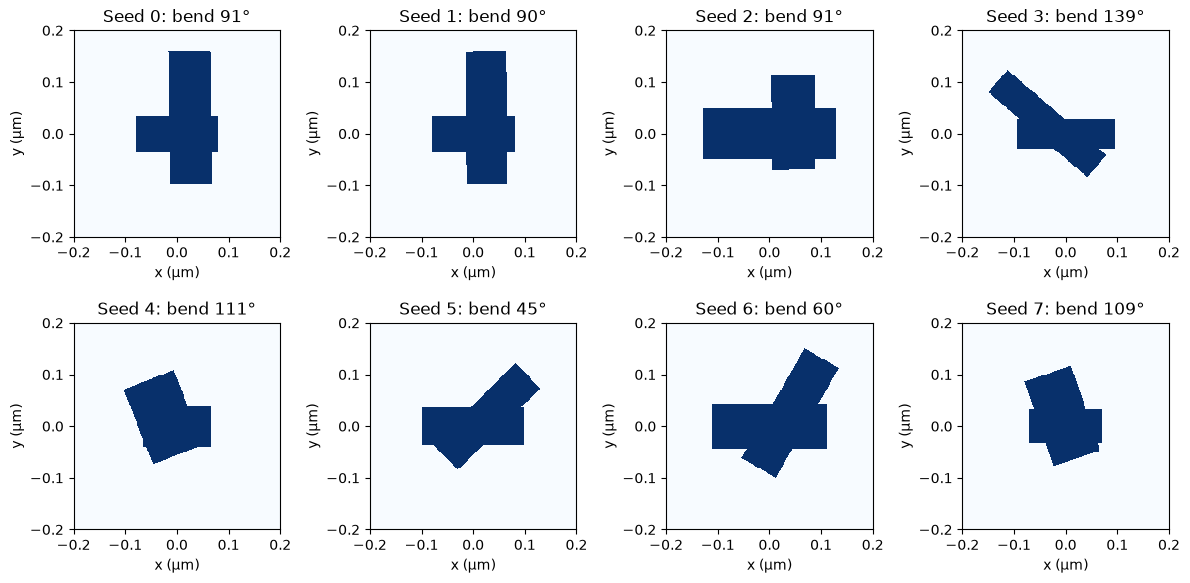

All design variables: {'length1': (0.12, 0.27), 'width1': (0.045, 0.11), 'length2': (0.12, 0.27), 'width2': (0.045, 0.11), 'bend_deg': (35.0, 155.0), 'junction_frac': (-0.23, 0.23)}


In [2]:
def show_mask(ax,p,theta=0.,title=None):
    q={k:torch.tensor(float(v),dtype=torch.float64) for k,v in p.items()}
    with torch.no_grad():
        m=twofin_mask(q,PHYS,220,theta,edge_um=.0015,hard=True).numpy()
    half=PHYS.period/2
    ax.imshow(m.T,origin='lower',extent=(-half,half,-half,half),
              cmap='Blues',vmin=0,vmax=1,interpolation='nearest')
    ax.set(xlabel='x (µm)',ylabel='y (µm)',title=title or 'Connected two-fin',
           aspect='equal',xlim=(-half,half),ylim=(-half,half))

rng=np.random.default_rng(SEED)
from scipy.special import expit, logit
sobol=qmc.Sobol(d=len(PARAM_KEYS),scramble=True,seed=SEED)
seeds=logit(np.clip(sobol.random_base2(int(np.ceil(np.log2(N_SCREEN))))[:N_SCREEN],.08,.92))
# Warm-start with the original slope-trained design, if available.
# Warm-start with earlier optimizer outputs, if available (re-ranked by the v3 solver).
for name in ('twofin_eta_checkpoint.npz','twofin_eta_checkpoint_v2.npz'):
    prior=OUT/name
    if prior.is_file():
        old_raw=np.load(prior,allow_pickle=False)['raw']
        if old_raw.shape==(len(PARAM_KEYS),) and np.isfinite(old_raw).all():
            seeds=np.vstack((old_raw[None,:],seeds))[:N_SCREEN]
            print(f'Prior geometry from {name} added to screening seeds.')
fig,axes=plt.subplots(2,4,figsize=(12,6))
for k,ax in enumerate(axes.flat):
    if k >= len(seeds):
        ax.axis('off');continue
    p={key:float(v) for key,v in design_from_raw(
        torch.tensor(seeds[k],dtype=torch.float64)).items()}
    show_mask(ax,p,title=f'Seed {k}: bend {p["bend_deg"]:.0f}°')
plt.tight_layout(); plt.show()
print('All design variables:', BOUNDS)

## 3 · Editable objective: maximize $\eta$ control, **not** anisotropy or gap

Write $p(u)=p_0+u\Delta p$ for the chosen physical modulation parameter and $u\in[-1,1]$. Five sample points catch interior peaks that an endpoint derivative misses.

- `ETA_OBJECTIVE='span'` maximizes $\max_u\eta(u)-\min_u\eta(u)$ (recommended for tunable-library design).
- `ETA_OBJECTIVE='slope'` maximizes the absolute endpoint secant $|[\eta(+1)-\eta(-1)]/2|$ (the original sensitivity objective).

**The loss contains no anisotropy, eigenvalue gap, power or nonnormality rewards.** The only optional extra term is `PHASE_WEIGHT` × mean squared deviation of the R←L circular-conversion phase across the modulation samples (relative to u=0), so that changing η does not also change the PB phase offset. Set `PHASE_WEIGHT=0` for pure η span. These metrics are logged. A permissive admissibility flag prevents saving numerically undefined eigenpolarization bases and virtually non-transmitting cells.

There is still an exact algebraic dependency: if $A=\|T-\operatorname{tr}(T)I/2\|_F/\|T\|_F$ and $g=|\lambda_+-\lambda_-|/\|T\|_F$, then

$$\eta^2=(A^2-g^2/2)/(A^2+g^2/2).$$

So $\eta$ cannot be varied while both $A$ and $g$ are fixed. Independence here means **no additional weighting of those quantities in the optical objective**.


In [3]:
OBJECTIVE_TAG = 'twofin_eta_span_flatphase_v3'
ETA_OBJECTIVE = 'span'      # 'span' or 'slope'
TRAIN_U = (-1., -0.5, 0., 0.5, 1.)
FAB_WEIGHT = 0.40
PHASE_WEIGHT = 0.25   # per rad^2 of conversion-phase deviation; 0 = eta only

# Eligibility for candidate selection only. These do NOT enter optical loss.
MIN_REPORT_POWER = 0.05
MIN_NUMERICAL_GAP = 0.002
MIN_NUMERICAL_NONSCALE = 0.002
MIN_ACCEPT_GAP = 0.05     # ACCEPT re-score: reject near-defective (near-EP) T
MIN_CONVERSION = 0.05     # ACCEPT re-score: PB phase is undefined without conversion
N_RESCORE = 4             # best training iterates per run re-scored with ACCEPT
_U_CIRC = torch.tensor([[1,1],[1j,-1j]],dtype=torch.complex128)/np.sqrt(2)

def optical_loss(S_samples):
    """Eta-only objective; all other Jones quantities are diagnostic."""
    ms=[jones_metrics(S[2:4,:2],min_relative_gap=MIN_NUMERICAL_GAP,
                      min_nonscalar=MIN_NUMERICAL_NONSCALE) for S in S_samples]
    eta=torch.stack([m['eta'] for m in ms])
    span=eta.max()-eta.min()
    slope=(eta[-1]-eta[0])/(TRAIN_U[-1]-TRAIN_U[0])
    if ETA_OBJECTIVE=='span':
        loss=-span
    elif ETA_OBJECTIVE=='slope':
        loss=-torch.abs(slope)
    else:
        raise ValueError("ETA_OBJECTIVE must be 'span' or 'slope'")
    U=_U_CIRC.to(device=S_samples[0].device,dtype=S_samples[0].dtype)
    conv=torch.stack([(U.conj().T@S[2:4,:2]@U)[0,1] for S in S_samples])  # R <- L
    dphi=torch.angle(conv/conv[len(conv)//2])
    phase_ms=(dphi**2).mean()
    loss=loss+PHASE_WEIGHT*phase_ms
    power=torch.stack([m['power'] for m in ms])
    gap=torch.stack([m['gap'] for m in ms])
    anis=torch.stack([m['anisotropy'] for m in ms])
    valid=torch.stack([m['eta_defined'] for m in ms]).all() & (
        power.min()>=MIN_REPORT_POWER)
    d=dict(slope=slope,eta_span=span,eta_min=eta.min(),
           eta_mid=eta[len(eta)//2],eta_max=eta.max(),
           gap_min=gap.min(),anisotropy_min=anis.min(),
           power_min=power.min(),valid=valid,
           phase_rms=torch.sqrt(phase_ms),conv_min=conv.abs().min())
    return loss,d

def objective(raw,settings):
    p=design_from_raw(raw)
    points=[vary(p,MOD,u) for u in TRAIN_U]
    mats=[solve_torch(pp,PHYS,settings) for pp in points]
    optical,d=optical_loss(mats)
    fab=torch.stack([geometry_penalty(pp,PHYS)[0] for pp in points]).mean()
    lo,hi=BOUNDS[MOD.parameter]
    in_bounds=all(bool((pp[MOD.parameter]>=lo)&(pp[MOD.parameter]<=hi))
                  for pp in points)
    d['valid']=d['valid'] & in_bounds
    d['fab_cost']=fab
    return optical+FAB_WEIGHT*fab,d,mats

def scalars(d):
    return {k:float(v.detach().cpu()) for k,v in d.items()
            if isinstance(v,torch.Tensor) and v.ndim==0}


def reference_score(raw):
    """Re-score a raw design with the accurate ACCEPT solver (no gradients), for selection only."""
    with torch.no_grad():
        r=torch.as_tensor(np.asarray(raw),device=DEVICE,dtype=device_dtype(ACCEPT))
        loss,d,_=objective(r,ACCEPT)
    out=dict(loss=float(loss.cpu()),**scalars(d))
    out['accepted']=bool(out['valid']) and out['gap_min']>=MIN_ACCEPT_GAP and out['conv_min']>=MIN_CONVERSION
    return out


## 4 · Screen, rerank, and optimize with verbose logs
First pass uses affordable RCWA. Survivors are reranked at higher order *before* Adam. The optimizer retains full trajectories, discards ill-defined candidates, and returns the best observed raw geometry. None of these lower-order rankings is evidence of converged physics.

After each candidate's coarse and refine runs, the `N_RESCORE` best training iterates of each stage (plus the final one) are **re-scored with `ACCEPT`** (higher order and raster). The winner is the accepted design with the best ACCEPT loss, never the best training loss. Accepted means valid, minimum gap ≥ `MIN_ACCEPT_GAP` and conversion amplitude ≥ `MIN_CONVERSION`.

In [4]:
checkpoint=OUT/'twofin_eta_checkpoint_v3.npz'
start_list=[]
if RUN_SCREEN:
    t0=time.perf_counter()
    for k,raw in enumerate(seeds):
        v=torch.tensor(raw,device=DEVICE,dtype=device_dtype(SCREEN))
        try:
            with torch.no_grad():
                loss,d,_=objective(v,SCREEN)
            row=dict(index=k,loss=float(loss.cpu()),raw=np.asarray(raw),
                     **scalars(d))
            if np.isfinite(row['loss']) and row['valid']:start_list.append(row)
        except (RuntimeError,ValueError) as err:
            print(f'Screen skip {k}: {str(err)[:140]}')
        if (k+1)%8==0:
            print(f'Screen {k+1}/{N_SCREEN} | valid {len(start_list)}')
    start_list.sort(key=lambda row:row['loss'])
    print('Screen seconds:',round(time.perf_counter()-t0,1))
    for row in start_list[:5]:
        print(f"score {row['loss']:+.4f} | eta-={row['eta_min']:.3f} "
              f"eta+={row['eta_max']:.3f} | Δη={row['eta_span']:.3f} "
              f"gap≥{row['gap_min']:.3f} | anis≥{row['anisotropy_min']:.3f}")
else:
    print('Screen disabled. Existing checkpoint required for later characterization.')


Screen 8/64 | valid 7


Screen 16/64 | valid 15


Screen 24/64 | valid 20


Screen 32/64 | valid 26


Screen 40/64 | valid 33


Screen 48/64 | valid 39


Screen 56/64 | valid 46


Screen 64/64 | valid 52
Screen seconds: 112.7
score -0.4812 | eta-=0.025 eta+=0.590 | Δη=0.565 gap≥0.370 | anis≥0.292
score -0.3697 | eta-=0.013 eta+=0.405 | Δη=0.391 gap≥0.265 | anis≥0.199
score -0.3601 | eta-=0.001 eta+=0.469 | Δη=0.468 gap≥0.390 | anis≥0.276
score -0.2178 | eta-=0.013 eta+=0.391 | Δη=0.378 gap≥0.337 | anis≥0.278
score -0.1532 | eta-=0.000 eta+=0.301 | Δη=0.301 gap≥0.335 | anis≥0.259


In [5]:
ranked=[]
if RUN_SCREEN and start_list:
    for i,row in enumerate(start_list[:max(N_KEEP*3,8)]):
        raw=torch.tensor(row['raw'],device=DEVICE,dtype=device_dtype(COARSE))
        try:
            with torch.no_grad():loss,d,_=objective(raw,COARSE)
            if bool(d['valid']):
                ranked.append(dict(raw=np.asarray(row['raw']),loss=float(loss.cpu()),
                                   **scalars(d)))
        except (RuntimeError,ValueError) as exc:print('Rerank skip:',str(exc)[:120])
    ranked.sort(key=lambda d:d['loss'])
    print('Higher-order shortlist:')
    for i,c in enumerate(ranked[:N_KEEP]):
        print(f" {i}: {c['loss']:+.4f}, Δη={c['eta_span']:.3f}, "
              f"min gap={c['gap_min']:.3f}, min anis={c['anisotropy_min']:.3f}")


Higher-order shortlist:
 0: -0.5423, Δη=0.594, min gap=0.366, min anis=0.293
 1: -0.4359, Δη=0.468, min gap=0.238, min anis=0.188
 2: -0.3763, Δη=0.462, min gap=0.387, min anis=0.273


In [6]:
def adam_run(raw0,opts,steps=50,lr=0.025,patience=30,label='Adam'):
    raw=torch.nn.Parameter(torch.tensor(raw0,device=DEVICE,dtype=device_dtype(opts)))
    opt=torch.optim.Adam([raw],lr=lr)
    best={'loss':float('inf'),'raw':None,'history':[]}
    since=0
    for it in range(steps):
        opt.zero_grad(set_to_none=True)
        try:
            loss,d,_=objective(raw,opts)
            if not bool(torch.isfinite(loss)):break
            score=float(loss.detach().cpu())
            loss.backward()
            if raw.grad is None or not bool(torch.isfinite(raw.grad).all()):break
            torch.nn.utils.clip_grad_norm_([raw],1.)
            record=dict(iteration=it,loss=score,raw=raw.detach().cpu().numpy().tolist(),**scalars(d))
            best['history'].append(record)
            if record['valid'] and score<best['loss']-1e-6:
                best.update(loss=score,raw=raw.detach().cpu().numpy().copy())
                since=0
            else:since+=1
            opt.step()
            if it==0 or (it+1)%10==0:
                print(f"{label} {it+1:3}/{steps}: loss={score:+.4f}, "
                      f"Δη={record['eta_span']:.3f}, dη/du={record['slope']:+.3f}, "
                      f"gap≥{record['gap_min']:.3f}, "
                      f"anis≥{record['anisotropy_min']:.3f}, "
                      f"P≥{record['power_min']:.3f}, Δφ_conv={record['phase_rms']:.3f} rad")
            if since>=patience:break
        except (RuntimeError,ValueError) as exc:
            print(f'{label}: terminated at iteration {it}: {exc}');break
    if best['raw'] is None:raise RuntimeError('No numerically admissible optimizer iteration')
    return best

def rescore(stage,history,k=N_RESCORE):
    """ACCEPT re-score of the k best valid training iterates of one run, plus its last iterate."""
    pool=sorted([h for h in history if h['valid']],key=lambda h:h['loss'])[:k]
    if history and all(h['iteration']!=history[-1]['iteration'] for h in pool):pool.append(history[-1])
    out=[]
    for h in pool:
        ref=reference_score(h['raw'])
        out.append(dict(stage=stage,iteration=h['iteration'],train_loss=h['loss'],
                        train_span=h['eta_span'],raw=h['raw'],ref=ref))
        print(f"   ACCEPT {stage} it {h['iteration']:3}: train Δη={h['eta_span']:.3f} -> "
              f"Δη={ref['eta_span']:.3f}, gap≥{ref['gap_min']:.3f}, |conv|≥{ref['conv_min']:.3f}, "
              f"Δφ={ref['phase_rms']:.3f} rad, accepted={ref['accepted']}")
    return out

trajectories=[]
rescored=[]
if RUN_OPTIMIZE and ranked:
    for i,entry in enumerate(ranked[:N_KEEP]):
        print(f'\n>>> Candidate {i+1}/{N_KEEP}')
        c=adam_run(entry['raw'],COARSE,COARSE_STEPS,lr=.02,
                   patience=40,label=f'C{i} coarse')
        r=adam_run(c['raw'],REFINE,REFINE_STEPS,lr=.006,
                   patience=20,label=f'C{i} refine')
        trajectories.append(dict(candidate=i,coarse=c,refine=r))
        for stage,run in (('coarse',c),('refine',r)):
            rescored+=[dict(candidate=i,**row) for row in rescore(stage,run['history'])]
    accepted=[row for row in rescored if row['ref']['accepted']]
    if not accepted:
        print('WARNING: no iterate passed ACCEPT; using the best ACCEPT loss among valid ones.')
        accepted=[row for row in rescored if row['ref']['valid']] or rescored
    winner=min(accepted,key=lambda row:row['ref']['loss'])
    best_raw=np.asarray(winner['raw'],float)
    print(f"Winner: candidate {winner['candidate']} {winner['stage']} it {winner['iteration']} | "
          f"ACCEPT Δη={winner['ref']['eta_span']:.3f}, loss={winner['ref']['loss']:+.4f}")
    np.savez_compressed(checkpoint,raw=best_raw,
        metadata=json.dumps(dict(physics=asdict(PHYS),modulation=asdict(MOD),
          objective_tag=OBJECTIVE_TAG, bounds=BOUNDS,seed=SEED,
          settings=asdict(REFINE),accept_settings=asdict(ACCEPT),
          phase_weight=PHASE_WEIGHT,winner={k:v for k,v in winner.items() if k!='raw'})),
        history=json.dumps([h for t in trajectories if t['candidate']==winner['candidate']
                            for h in t['refine']['history']]),
        rescored=json.dumps(rescored))
    print('Saved:',checkpoint)
elif checkpoint.is_file():
    best_raw=np.load(checkpoint,allow_pickle=False)['raw']
    print('Loaded:',checkpoint)
else:
    best_raw=None
    print('No optimized result. Turn on screening/optimization or provide a checkpoint.')



>>> Candidate 1/3


C0 coarse   1/60: loss=-0.5423, Δη=0.594, dη/du=+0.001, gap≥0.366, anis≥0.293, P≥0.613, Δφ_conv=0.454 rad


C0 coarse  10/60: loss=-0.5259, Δη=0.604, dη/du=+0.003, gap≥0.424, anis≥0.300, P≥0.515, Δφ_conv=0.558 rad


C0 coarse  20/60: loss=-0.6844, Δη=0.739, dη/du=+0.007, gap≥0.377, anis≥0.307, P≥0.548, Δφ_conv=0.465 rad


C0 coarse  30/60: loss=-0.6823, Δη=0.738, dη/du=+0.006, gap≥0.334, anis≥0.313, P≥0.598, Δφ_conv=0.470 rad


...

   ACCEPT refine it  21: train Δη=0.950 -> Δη=0.675, gap≥0.478, |conv|≥0.111, Δφ=0.885 rad, accepted=True


   ACCEPT refine it  19: train Δη=0.948 -> Δη=0.673, gap≥0.477, |conv|≥0.112, Δφ=0.876 rad, accepted=True


   ACCEPT refine it  16: train Δη=0.933 -> Δη=0.695, gap≥0.475, |conv|≥0.100, Δφ=0.866 rad, accepted=True


   ACCEPT refine it  14: train Δη=0.926 -> Δη=0.705, gap≥0.475, |conv|≥0.095, Δφ=0.862 rad, accepted=True


   ACCEPT refine it  29: train Δη=0.886 -> Δη=0.614, gap≥0.478, |conv|≥0.144, Δφ=0.837 rad, accepted=True
Winner: candidate 2 coarse it 56 | ACCEPT Δη=0.799, loss=-0.7085
Saved: results/twofin_eta_transport/twofin_eta_checkpoint_v3.npz


## 5 · Inspect the optimized connected two-fin structure and training curves

Physical parameters: {'length1': 0.15752692867676765, 'width1': 0.06738258952054155, 'length2': 0.2587544452516357, 'width2': 0.08086714271278195, 'bend_deg': 88.03871919486221, 'junction_frac': 0.15155616056611002}
Geometric connectedness: True; overlap area: 5452.2 nm²


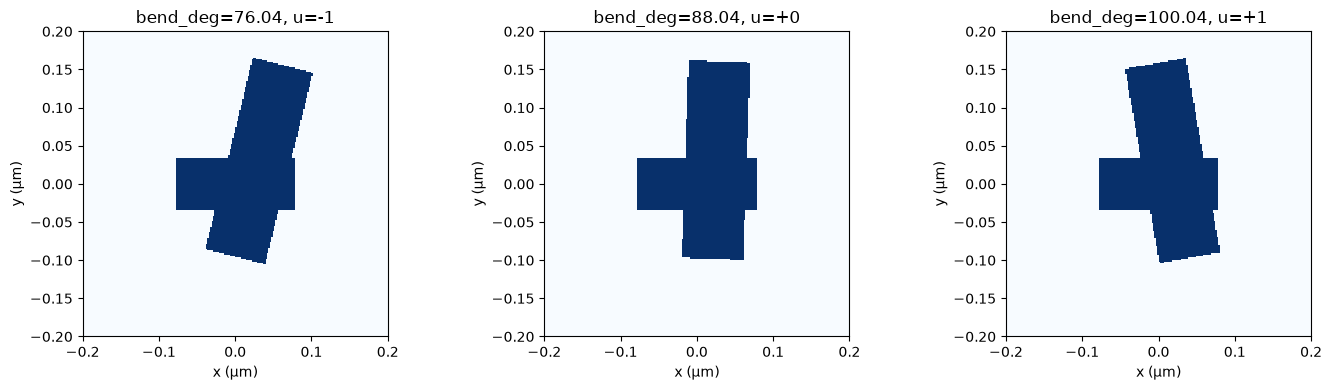

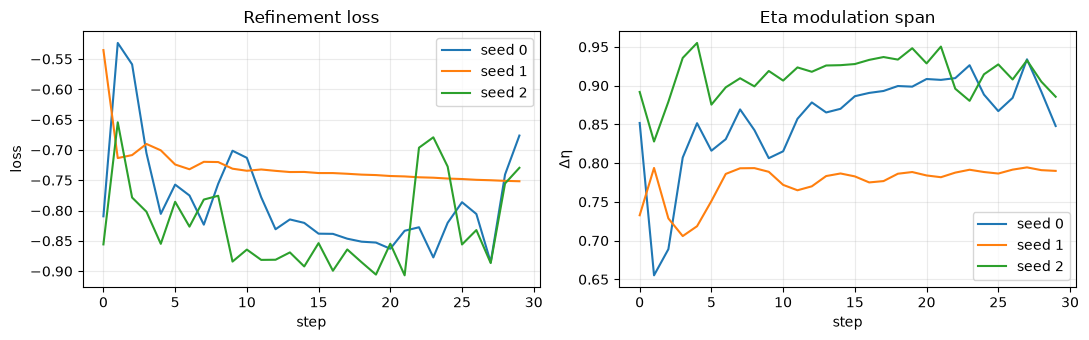

In [7]:
if best_raw is not None:
    pbest=design_from_raw(torch.tensor(best_raw,device=DEVICE,dtype=device_dtype(REFINE)))
    geom={key:float(v) for key,v in pbest.items()}
    overlap_area,connected=check_connected(geom)
    print('Physical parameters:',geom)
    print(f'Geometric connectedness: {connected}; overlap area: {overlap_area*1e6:.1f} nm²')
    fig,axs=plt.subplots(1,3,figsize=(14,4))
    for ax,u in zip(axs,(-1.,0.,1.)):
        pp={key:float(v) for key,v in vary(pbest,MOD,u).items()}
        show_mask(ax,pp,title=f'{MOD.parameter}={pp[MOD.parameter]:.2f}, u={u:+.0f}')
    plt.tight_layout();plt.show()
    if trajectories:
        fig,axs=plt.subplots(1,2,figsize=(11,3.5))
        for t in trajectories:
            hist=t['refine']['history']; it=[r['iteration'] for r in hist]
            axs[0].plot(it,[r['loss'] for r in hist],label=f"seed {t['candidate']}")
            axs[1].plot(it,[r['eta_span'] for r in hist],label=f"seed {t['candidate']}")
        axs[0].set(title='Refinement loss',xlabel='step',ylabel='loss')
        axs[1].set(title='Eta modulation span',xlabel='step',ylabel='Δη')
        for ax in axs:ax.legend();ax.grid(alpha=.25)
        plt.tight_layout();plt.show()


## 5b · Full complex 4×4 S, Jones eigenpolarizations, and physical consistency
The four-channel result preserves complex global phase. Reciprocity and unitarity should be checked for the full matrix, not the transmission block alone. This is the `ACCEPT`-order, area-fraction-mask, NV-factorized **single-layer** response.

In [8]:
S_baseline=None
if best_raw is not None:
    with torch.no_grad():
        S_baseline=solve_torch(pbest,PHYS,ACCEPT).detach().cpu().numpy()
    T=S_baseline[2:4,:2]; R=S_baseline[:2,:2]
    vals,V=np.linalg.eig(T); V=V/np.linalg.norm(V,axis=0,keepdims=True)
    print('S (bottom x/y, top x/y):\n',np.array2string(S_baseline,precision=4))
    print('T eigenvalues:',vals)
    print('Right eigenpolarizations (Stokes S2,S3,S1):',
          [np.round(stokes(V[:,j]),4) for j in range(2)])
    print('η direct:',eta_from_eigenvectors(T)[0],
          'η formula:',numpy_metrics(S_baseline)['eta'],
          'defined:',bool(jones_metrics(torch.tensor(T,dtype=torch.complex128))['eta_defined']))
    print('Unitary Frobenius error:',np.linalg.norm(S_baseline.conj().T@S_baseline-np.eye(4)))
    print('Reciprocity Frobenius error:',np.linalg.norm(S_baseline-S_baseline.T))
    print('Forward x/y transmitted powers:',(np.abs(T)**2).sum(axis=0))
    print('Forward x/y reflected powers:',(np.abs(R)**2).sum(axis=0))
    paths=export_layout(geom,PHYS,OUT/'twofin_connected_mask')
    print('Layout:',paths)


S (bottom x/y, top x/y):
 [[ 0.1013+0.0778j  0.2242+0.0819j -0.1272-0.89j    0.322 +0.1216j]
 [ 0.2242+0.0819j -0.1436-0.0311j  0.322 +0.1216j  0.6947-0.566j ]
 [-0.1272-0.89j    0.322 +0.1216j  0.1013+0.0778j  0.2242+0.0819j]
 [ 0.322 +0.1216j  0.6947-0.566j   0.2242+0.0819j -0.1436-0.0311j]]
T eigenvalues: [-0.23832084-0.93051021j  0.80579667-0.52547466j]
Right eigenpolarizations (Stokes S2,S3,S1): [array([-0.6146,  0.0069,  0.7888]), array([ 0.6146,  0.0069, -0.7888])]
η direct: 0.006923450046654396 η formula: 0.006923450047374342 defined: True
Unitary Frobenius error: 1.3906091299644107e-10
Reciprocity Frobenius error: 1.927670368195779e-11
Forward x/y transmitted powers: [0.92669413 0.92144397]
Forward x/y reflected powers: [0.07330587 0.07855603]
Layout: {'svg': 'results/twofin_eta_transport/twofin_connected_mask.svg', 'gds': 'results/twofin_eta_transport/twofin_connected_mask.gds'}


## 5c · What evanescent orders mean for $\eta$

For a 400 nm cell illuminated normally at 633 nm, exterior diffraction order $(m,n)$ propagates only if $\sqrt{m^2+n^2}\lambda\le n_{\mathrm{clad}}\Lambda$. A 400 nm cell in silica has **only one propagating spatial order**. The other orders are evanescent **in the exterior** but are coupled and retained by TORCWA inside the patterned material.

The overlap computed here describes the **specular far-field $2\times2$ transmission Jones matrix**, not the eigenpolarization of the microscopic near field. Higher Fourier orders can still change this matrix through coupling. We therefore validate convergence rather than adding evanescent orders as fictitious external Jones channels.

One more caveat: the supercell and finite-array sections have different diffraction channels. A supercell's specular $T$ is not the whole transmitted optical field.


In [9]:
cutoffs=diffraction_audit(PHYS)
for region,d in cutoffs.items():
    if isinstance(d,dict):
        print(f'{region:14} n={d["index"]:.3f}, first-order cutoff '
              f'λ={1000*d["first_order_cutoff_um"]:.1f} nm, '
              f'propagating={d["first_order_propagating"]}, '
              f'evanescent 1/e length={1000*d["first_order_decay_um"]:.1f} nm')
print('Exterior 4x4 S contains all propagating channels:',
      cutoffs['exterior_only_specular'])
# Check formula against an independent eigenvector calculation, not RCWA itself.
rng_check=np.random.default_rng(714)
errors=[]
for _ in range(120):
    J=(rng_check.normal(size=(2,2))+1j*rng_check.normal(size=(2,2)))
    J*=10.**rng_check.uniform(-7,3)
    eta_direct=eta_from_eigenvectors(J)[0]
    eta_formula=float(jones_metrics(torch.as_tensor(J,dtype=torch.complex128))['eta'])
    errors.append(abs(eta_direct-eta_formula))
print('Independent random-matrix η identity, maximum absolute error:',max(errors))
assert max(errors)<1e-9
scalar_check=jones_metrics(torch.eye(2,dtype=torch.complex128))
print('Exact scalar T has a uniquely defined eigenpolarization pair:',
      bool(scalar_check['eta_defined']))
assert not bool(scalar_check['eta_defined'])


bottom         n=1.460, first-order cutoff λ=584.0 nm, propagating=False, evanescent 1/e length=165.0 nm
top            n=1.460, first-order cutoff λ=584.0 nm, propagating=False, evanescent 1/e length=165.0 nm
background     n=1.460, first-order cutoff λ=584.0 nm, propagating=False, evanescent 1/e length=165.0 nm
fin_reference  n=2.584, first-order cutoff λ=1033.6 nm, propagating=True, evanescent 1/e length=inf nm
Exterior 4x4 S contains all propagating channels: True
Independent random-matrix η identity, maximum absolute error: 2.670259846571099e-13
Exact scalar T has a uniquely defined eigenpolarization pair: False


## 6 · RCWA convergence (NV factorization) and solver cross-check
We explicitly converge $\eta$, eigenvalue gap, non-scalar strength, power, and matrix norm across orders. Large apparent $d\eta/d\phi$ caused by nearly scalar $T$ must not be reported as physical control.
The order convergence test and the independent raster test are both important:
the first probes *Fourier-harmonic truncation*, the second probes *pixelated
geometry accuracy*. The two effects must not be varied together when diagnosing
a discrepancy.

The cross-check after the order sweep compares the area-fraction mask with an 8×8 supersampled mask, the binary staircase, and plain-Laurent TORCWA at the same order. Laurent disagreeing with NV is expected and is the reason for NV.

order 8: dη/du=+0.0044; η=[0.028 0.029 0.037], min gap=0.478, min anis=0.338, min P=0.734, direct-analytic η err<=1.8e-13


order 10: dη/du=+0.0043; η=[0.027 0.012 0.036], min gap=0.469, min anis=0.332, min P=0.736, direct-analytic η err<=4.1e-13


order 12: dη/du=+0.0042; η=[0.028 0.007 0.036], min gap=0.471, min anis=0.334, min P=0.736, direct-analytic η err<=7.2e-13


order 14: dη/du=+0.0026; η=[0.028 0.005 0.033], min gap=0.472, min anis=0.334, min P=0.736, direct-analytic η err<=1.1e-12


order 16: dη/du=+0.0033; η=[0.028 0.006 0.035], min gap=0.472, min anis=0.334, min P=0.736, direct-analytic η err<=8.6e-13


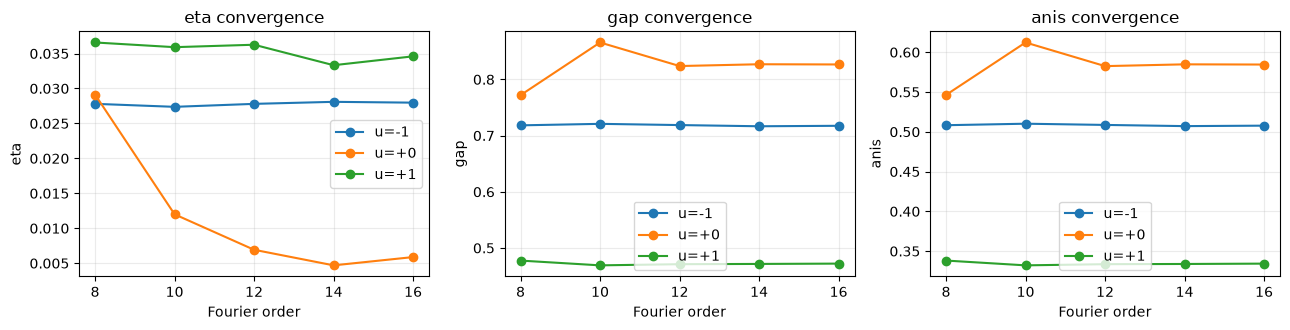

Solver cross-check at order 12, raster 256, η at u=-1,0,+1:


  NV area-fraction       [0.0278 0.0069 0.0363]


  NV supersampled        [0.0274 0.0214 0.0363]


  NV binary              [0.0306 0.0461 0.0428]


  Laurent area-fraction  [0.0298 0.822  0.0217]


In [10]:
verification=[]
if best_raw is not None and RUN_CONVERGENCE:
    for order in VERIFY_ORDERS:
        opts=RCWA(order=order,raster=VERIFY_RASTER,precision='complex128',device=DEVICE)
        point=[]
        with torch.no_grad():
            for u in (-1.,0.,1.):
                mat=solve_torch(vary(pbest,MOD,u),PHYS,opts)
                arr=mat.detach().cpu().numpy()
                d=numpy_metrics(arr)
                direct=eta_from_eigenvectors(arr[2:4,:2])[0]
                d['direct_eta_error']=abs(direct-d['eta'])
                point.append(d)
        slope=(point[2]['eta']-point[0]['eta'])/2
        row=dict(order=order,slope=slope,
            eta=[d['eta'] for d in point],gap=[d['gap'] for d in point],
            anis=[d['anisotropy'] for d in point],power=[d['power'] for d in point])
        verification.append(row)
        print(f"order {order}: dη/du={slope:+.4f}; "
              f"η={np.round(row['eta'],3)}, min gap={min(row['gap']):.3g}, "
              f"min anis={min(row['anis']):.3g}, min P={min(row['power']):.3g}, "
              f"direct-analytic η err<={max(q['direct_eta_error'] for q in point):.1e}")
    fig,axes=plt.subplots(1,3,figsize=(13,3.4))
    for ax,name in zip(axes,('eta','gap','anis')):
        for j,u in enumerate((-1.,0.,1.)):
            ax.plot([r['order'] for r in verification],
                [r[name][j] for r in verification],marker='o',label=f'u={u:+.0f}')
        ax.set(xlabel='Fourier order',ylabel=name,title=name+' convergence')
        ax.legend();ax.grid(alpha=.25)
    plt.tight_layout();plt.show()

    print('Solver cross-check at order 12, raster 256, η at u=-1,0,+1:')
    base=RCWA(order=12,raster=VERIFY_RASTER,precision='complex128',device=DEVICE)
    for label,o in (('NV area-fraction',base),('NV supersampled',replace(base,mask='ss')),
                    ('NV binary',replace(base,mask='hard')),('Laurent area-fraction',replace(base,factorization='laurent'))):
        with torch.no_grad():
            e=[numpy_metrics(solve_torch(vary(pbest,MOD,u),PHYS,o).cpu().numpy())['eta'] for u in (-1.,0.,1.)]
        print(f'  {label:22} {np.round(e,4)}')


## 6b · Independent raster convergence and square-lattice rotation test

Numerical reliability needs two **separate** checks. Increasing RCWA Fourier order at fixed raster checks spectral truncation; increasing raster at fixed Fourier order checks the shape's discretization. The optional raster test is independent of the normal order sweep.

For a **square lattice** at normal incidence, rotating the complete unit-cell motif by **exactly 90°** should transform its Jones matrix by $T_{90}=R_{90}T_0R_{90}^{-1}$ (up to numerical error). In particular, $\eta(T_{90})=\eta(T_0)$. A failure of this inexpensive $C_4$ symmetry test indicates a discretization, geometry or polarization-basis problem and should be resolved before interpreting $\eta(\theta)$.

At arbitrary angles, the fixed square lattice need not be rotationally covariant; strong $\theta$ dependence can be physical through periodic electromagnetic coupling.


In [11]:
rotation_audit=[]
if best_raw is not None and RUN_ROTATION_C4_AUDIT:
    R90=np.array([[0.,-1.],[1.,0.]])
    for order in (VERIFY_ORDERS[0],VERIFY_ORDERS[-1]):
        opts=RCWA(order=order,raster=VERIFY_RASTER,precision='complex128',device=DEVICE)
        with torch.no_grad():
            S0=solve_torch(pbest,PHYS,opts,theta_deg=0.).cpu().numpy()
            S90=solve_torch(pbest,PHYS,opts,theta_deg=90.).cpu().numpy()
        T0,T90=S0[2:4,:2],S90[2:4,:2]
        ideal=R90@T0@R90.T
        residual=np.linalg.norm(T90-ideal)/max(np.linalg.norm(T0),1e-15)
        eta_error=abs(eta_from_eigenvectors(T0)[0]-eta_from_eigenvectors(T90)[0])
        rotation_audit.append(dict(order=order,T_error=residual,eta_error=eta_error))
        print(f'C4 order {order}: relative Jones error {residual:.3e}; '
              f'|η90-η0| {eta_error:.3e}')
    if rotation_audit[-1]['T_error']>1e-2:
        print('WARNING: 90-degree covariance is not well converged.')
raster_audit=[]
if best_raw is not None and RUN_RASTER_AUDIT:
    order=VERIFY_ORDERS[-1]
    for raster in (128,192,256,384):
        opts=RCWA(order=order,raster=raster,precision='complex128',device=DEVICE)
        values=[]
        with torch.no_grad():
            for u in (-1.,0.,1.):
                S=solve_torch(vary(pbest,MOD,u),PHYS,opts)
                values.append(numpy_metrics(S.cpu().numpy())['eta'])
        raster_audit.append(dict(order=order,raster=raster,eta=values))
        print(f'order={order} raster={raster}: η={np.round(values,4)} '
              f'endpoint slope={(values[-1]-values[0])/2:+.4f}')


C4 order 8: relative Jones error 1.225e-09; |η90-η0| 3.782e-10


C4 order 16: relative Jones error 1.603e-09; |η90-η0| 5.194e-10


order=16 raster=128: η=[0.0248 0.0579 0.0297] endpoint slope=+0.0025


order=16 raster=192: η=[0.0277 0.0006 0.0312] endpoint slope=+0.0018


order=16 raster=256: η=[0.028  0.0059 0.0346] endpoint slope=+0.0033


order=16 raster=384: η=[0.0291 0.0289 0.0365] endpoint slope=+0.0037


## 7 · Dense physical modulation sweep and all-parameter sensitivities
The model trains on five points, but characterization uses independent intermediate points. The slope from two ends is not sufficient if the function has abrupt jumps or a hidden degeneracy. Sensitivities are reported with their physical units, not mixed indiscriminately in one norm.

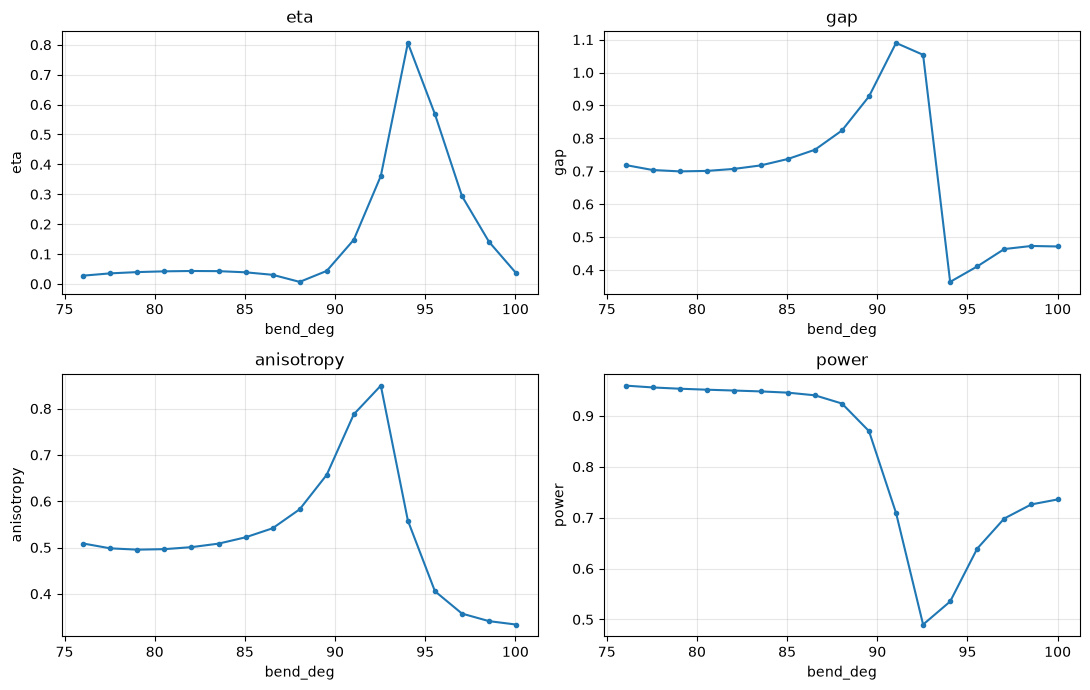

Finite-sweep η range: 0.006923450047374342 0.8062159491085228 | dη/dbend_deg near center: 0.0043540569511790654


In [12]:
mod_curve=[]
CHAR=RCWA(order=CHAR_ORDER,raster=VERIFY_RASTER,precision='complex128',device=DEVICE)
if best_raw is not None and RUN_DENSE_MODULATION:
    for u in np.linspace(-1,1,17):
        with torch.no_grad():S=solve_torch(vary(pbest,MOD,float(u)),PHYS,CHAR)
        met=numpy_metrics(S.detach().cpu().numpy())
        mod_curve.append(dict(u=float(u),value=geom[MOD.parameter]+float(u)*MOD.amplitude,
                              S=S.detach().cpu().numpy(),**met))
    fig,axs=plt.subplots(2,2,figsize=(11,7))
    for ax,name in zip(axs.flat,('eta','gap','anisotropy','power')):
        ax.plot([r['value'] for r in mod_curve],[r[name] for r in mod_curve],'-o',ms=3)
        ax.set(xlabel=MOD.parameter,ylabel=name,title=name);ax.grid(alpha=.3)
    plt.tight_layout();plt.show()
    vals=[r['eta'] for r in mod_curve]
    print('Finite-sweep η range:',min(vals),max(vals),
          '| dη/d'+MOD.parameter+' near center:',
          (vals[9]-vals[7])/(mod_curve[9]['value']-mod_curve[7]['value']))


In [13]:
parameter_sensitivity=[]
# Physical steps: length/width in µm, bend in degrees, junction dimensionless.
physical_steps={'length1':.008,'width1':.004,'length2':.008,
                'width2':.004,'bend_deg':4.0,'junction_frac':.035}
if best_raw is not None and RUN_PARAMETER_GRADIENTS:
    for key,step in physical_steps.items():
        etas=[];diagnostics=[]
        for sign in (-1,+1):
            varied=dict(pbest)
            varied[key]=pbest[key]+sign*step
            with torch.no_grad():S=solve_torch(varied,PHYS,CHAR)
            met=numpy_metrics(S.detach().cpu().numpy())
            etas.append(met['eta']);diagnostics.append(met)
        slope=(etas[1]-etas[0])/(2*step)
        parameter_sensitivity.append((key,slope,etas,
            min(x['gap'] for x in diagnostics)))
        print(f'{key:15} dη/dp={slope:+.4g} (physical units), '
              f'|Δη| for tested interval={abs(etas[1]-etas[0]):.3f}, '
              f'η(-,+)={np.round(etas,3)}, gap_min={parameter_sensitivity[-1][-1]:.3g}')


length1         dη/dp=+36.93 (physical units), |Δη| for tested interval=0.591, η(-,+)=[0.076 0.667], gap_min=0.444


width1          dη/dp=+45.23 (physical units), |Δη| for tested interval=0.362, η(-,+)=[0.092 0.453], gap_min=0.574


length2         dη/dp=+42.8 (physical units), |Δη| for tested interval=0.685, η(-,+)=[0.104 0.789], gap_min=0.367


width2          dη/dp=+34.41 (physical units), |Δη| for tested interval=0.275, η(-,+)=[0.106 0.381], gap_min=0.48


bend_deg        dη/dp=+0.02841 (physical units), |Δη| for tested interval=0.227, η(-,+)=[0.042 0.269], gap_min=0.723


junction_frac   dη/dp=-1.067 (physical units), |Δη| for tested interval=0.075, η(-,+)=[0.119 0.045], gap_min=0.706


## 7b · Held-out fabrication robustness of $\eta$ control

Perturb both arm lengths and widths (independently), the bend setpoint, and junction location. The modulation excursion itself is preserved. Report the *distribution* of gradients, plus the worst gap/power/anisotropy across the two modulation endpoints. A sharp derivative that vanishes with a few nanometres of fabrication error is not useful parameter control.

In [14]:
heldout=[]
if best_raw is not None and RUN_ROBUSTNESS:
    perturb_rng=np.random.default_rng(SEED+778)
    rob_opts=replace(CHAR,raster=192)
    for trial in range(10):
        varied={k:v.detach().clone() for k,v in pbest.items()}
        errors=dict(length1=0.004,width1=0.003,length2=0.004,
                    width2=0.003,bend_deg=2.0,junction_frac=0.015)
        for k,sd in errors.items():
            varied[k]=varied[k]+float(perturb_rng.normal(scale=sd))
        row=[]
        with torch.no_grad():
            for u in (-1.,0.,1.):
                S=solve_torch(vary(varied,MOD,u),PHYS,rob_opts)
                row.append(numpy_metrics(S.detach().cpu().numpy()))
        heldout.append(dict(trial=trial,slope=(row[2]['eta']-row[0]['eta'])/2,
            eta=[d['eta'] for d in row],min_gap=min(d['gap'] for d in row),
            min_anis=min(d['anisotropy'] for d in row),
            min_power=min(d['power'] for d in row)))
    print('dη/du over held-out perturbations:',
          np.round([r['slope'] for r in heldout],4))
    print('Median |slope|:', np.median([abs(r['slope']) for r in heldout]))
    print('Worst gap:',min(r['min_gap'] for r in heldout))


dη/du over held-out perturbations: [ 0.0173  0.0254  0.0632  0.1929  0.026   0.0651  0.0242 -0.0007  0.0119
  0.0894]
Median |slope|: 0.025738044607576373
Worst gap: 0.3550312952718398


## 8 · Polarization eigenvectors and Poincaré paths
The right eigenpolarizations are characterized at each physical modulation, with left vectors defined biorthogonally. The complex kinematic Wilson product over a parameter cycle is **not** yet a physical optical phase of a transverse array.

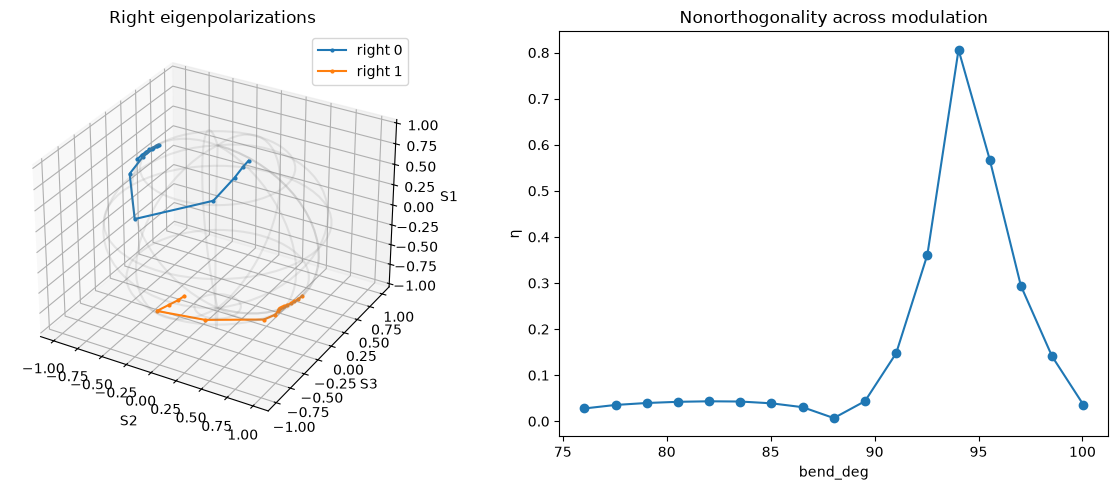

In [15]:
if mod_curve:
    fig=plt.figure(figsize=(12,5))
    ax=fig.add_subplot(121,projection='3d')
    theta=np.linspace(0,2*np.pi,60);psi=np.linspace(0,np.pi,31)
    X=np.outer(np.cos(theta),np.sin(psi));Y=np.outer(np.sin(theta),np.sin(psi))
    Z=np.outer(np.ones(len(theta)),np.cos(psi))
    ax.plot_wireframe(X,Y,Z,color='gray',alpha=.16,rstride=7,cstride=7)
    paths=[[],[]]
    for r in mod_curve:
        _,e,V=eta_from_eigenvectors(r['S'][2:4,0:2])
        for i in range(2):paths[i].append(stokes(V[:,i]))
    for i,pp in enumerate(paths):
        pp=np.asarray(pp);ax.plot(pp[:,0],pp[:,1],pp[:,2],'-o',ms=2,label=f'right {i}')
    ax.set(xlabel='S2',ylabel='S3',zlabel='S1',title='Right eigenpolarizations')
    ax.legend()
    axs=fig.add_subplot(122)
    axs.plot([r['value'] for r in mod_curve],[r['eta'] for r in mod_curve],'-o')
    axs.set(xlabel=MOD.parameter,ylabel='η',title='Nonorthogonality across modulation')
    plt.tight_layout();plt.show()


## 9 · Two-parameter library: $\eta(\phi,\theta)$ and PB conversion

Rotate the **same connected geometry** while modulating its bend angle. A true rotationally covariant isolated Jones element has spin-flipped coefficients with $\pm2\theta$ winding. A motif inside an unrotated square lattice need not satisfy exact rotational covariance, so actual RCWA phase residuals and conversion amplitudes are measured. We do **not** infer converted amplitude from $\eta$ alone.

PB library 1/5 completed


PB library 2/5 completed


PB library 3/5 completed


PB library 4/5 completed


PB library 5/5 completed


/tmp/ipykernel_330932/1780015510.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  for ax in axs:ax.legend(fontsize=7);ax.grid(alpha=.2)


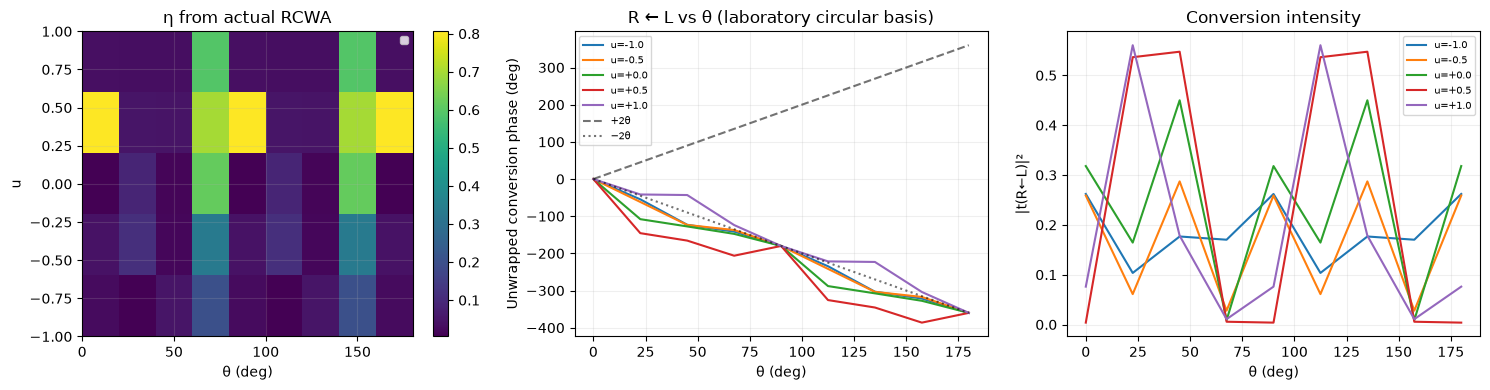

u=-1.0: PB residual circular RMS 0.288 rad; eta θ range [0.00449,0.202]
u=-0.5: PB residual circular RMS 0.308 rad; eta θ range [0.0172,0.333]
u=+0.0: PB residual circular RMS 0.611 rad; eta θ range [0.00692,0.616]
u=+0.5: PB residual circular RMS 1.19 rad; eta θ range [0.0476,0.806]
u=+1.0: PB residual circular RMS 0.398 rad; eta θ range [0.0331,0.59]


In [16]:
library={}
u_axis=np.linspace(-1,1,5)
theta_axis=np.linspace(0,180,9)  # radians converted internally
if best_raw is not None and RUN_PB_LIBRARY:
    for i,u in enumerate(u_axis):
        for j,theta in enumerate(theta_axis):
            with torch.no_grad():
                S=solve_torch(vary(pbest,MOD,float(u)),PHYS,CHAR,
                              theta_deg=float(theta))
            S=S.detach().cpu().numpy()
            library[(i,j)]={'u':float(u),'theta':float(theta),'S':S,
                            **numpy_metrics(S),'Jcirc':circular_conversion(S)}
        print(f'PB library {i+1}/{len(u_axis)} completed')
    eta_grid=np.array([[library[(i,j)]['eta'] for j in range(len(theta_axis))]
                       for i in range(len(u_axis))])
    coeff=np.array([[library[(i,j)]['Jcirc'][0,1] for j in range(len(theta_axis))]
                    for i in range(len(u_axis))])
    fig,axs=plt.subplots(1,3,figsize=(15,4))
    im=axs[0].imshow(eta_grid,aspect='auto',origin='lower',
        extent=(theta_axis[0],theta_axis[-1],u_axis[0],u_axis[-1]))
    axs[0].set(xlabel='θ (deg)',ylabel='u',title='η from actual RCWA');fig.colorbar(im,ax=axs[0])
    for i,u in enumerate(u_axis):
        phases=np.unwrap(np.angle(coeff[i,:]/coeff[i,0]))
        axs[1].plot(theta_axis,np.degrees(phases),label=f'u={u:+.1f}')
        axs[2].plot(theta_axis,np.abs(coeff[i,:])**2,label=f'u={u:+.1f}')
    axs[1].plot(theta_axis,2*theta_axis,'k--',alpha=.55,label='+2θ')
    axs[1].plot(theta_axis,-2*theta_axis,'k:',alpha=.55,label='−2θ')
    axs[1].set(xlabel='θ (deg)',ylabel='Unwrapped conversion phase (deg)',
               title='R ← L vs θ (laboratory circular basis)')
    axs[2].set(xlabel='θ (deg)',ylabel='|t(R←L)|²',title='Conversion intensity')
    for ax in axs:ax.legend(fontsize=7);ax.grid(alpha=.2)
    plt.tight_layout();plt.show()
    for i,u in enumerate(u_axis):
        if np.min(np.abs(coeff[i])**2)<1e-4:
            print(f'Warning u={u:+.1f}: near-zero conversion makes PB phase fragile')
        phi=np.unwrap(np.angle(coeff[i,:]/coeff[i,0]))
        ideal=-2*np.deg2rad(theta_axis)
        residual=np.angle(np.exp(1j*(phi-ideal)))
        print(f'u={u:+.1f}: PB residual circular RMS {np.sqrt(np.mean(residual**2)):.3g} rad; '
              f'eta θ range [{eta_grid[i,:].min():.3g},{eta_grid[i,:].max():.3g}]')


## 10 · Assemble a single-layer array: local Jones approximation
Every pixel has its own `(u, θ)`. This predicts complex transmitted near-field pixels and their coherent far field. **The photons are not forced to visit pixels in order.** This experiment establishes complex-amplitude control, not geometric holonomy.

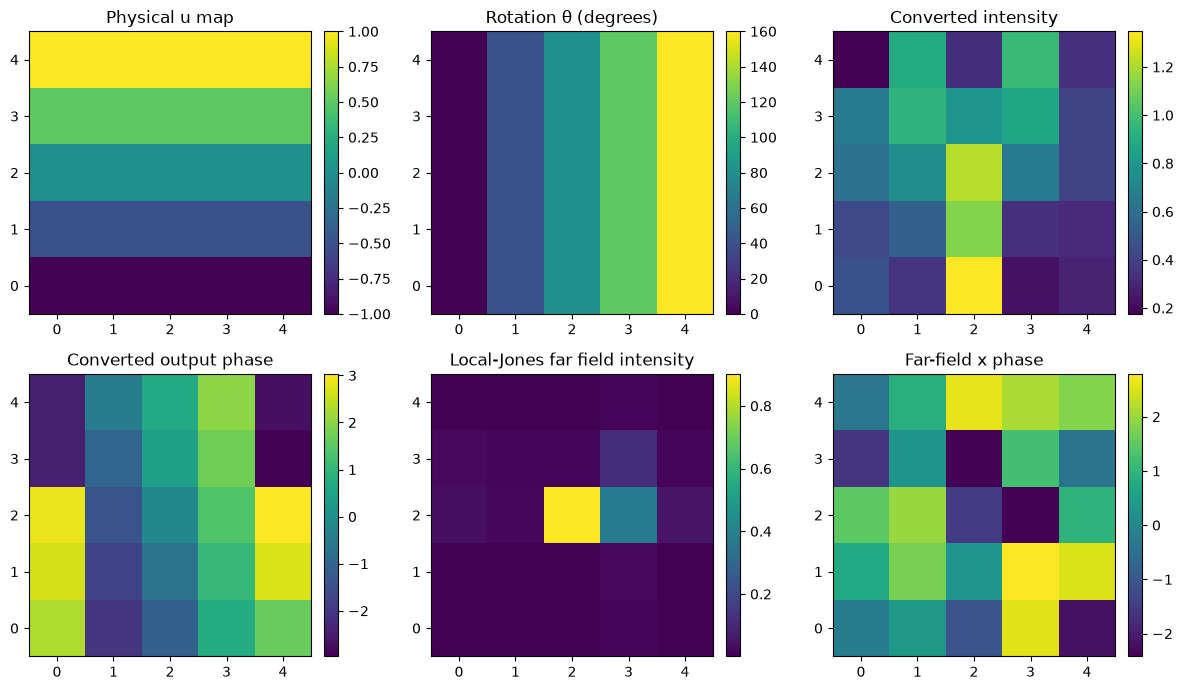

In [17]:
# Square 5x5 test: eta ramp along rows, theta ramp along columns.
side=5
arr_u=np.repeat(np.linspace(-1,1,side)[:,None],side,axis=1)
arr_theta=np.repeat(np.linspace(0,160,side)[None,:],side,axis=0)
Tmap=None
if library and RUN_ARRAY_LOCAL:
    def lookup_rcwa(u,theta):
        # Exact library values at the requested grid coordinates.
        i=np.argmin(abs(u_axis-u));j=np.argmin(abs(theta_axis-theta))
        if abs(u-u_axis[i])>1e-9 or abs(theta-theta_axis[j])>1e-9:
            with torch.no_grad():S=solve_torch(vary(pbest,MOD,u),PHYS,CHAR,
                                              theta_deg=theta)
            return S.detach().cpu().numpy()[2:4,0:2]
        return library[(i,j)]['S'][2:4,0:2]
    Tmap=local_array(arr_u,arr_theta,lookup_rcwa)
    E,F,I=far_field_local(Tmap,input_jones=(1,1j))  # + circular in lab convention
    U=np.array([[1,1],[1j,-1j]])/np.sqrt(2)
    Ecirc=np.einsum('ab,ijb->ija',U.conj().T,E)
    fig,axs=plt.subplots(2,3,figsize=(12,7))
    for ax,dat,title in zip(axs.flat,
        (arr_u,arr_theta,np.abs(Ecirc[:,:,1])**2,
         np.angle(Ecirc[:,:,1]),I,np.angle(F[:,:,0])),
        ('Physical u map','Rotation θ (degrees)','Converted intensity',
         'Converted output phase','Local-Jones far field intensity','Far-field x phase')):
        im=ax.imshow(dat,origin='lower',cmap='viridis');ax.set_title(title)
        fig.colorbar(im,ax=ax,fraction=.046,pad=.04)
    plt.tight_layout();plt.show()


## 11 · Optional full-wave **periodic supercell**, with diffraction orders
A single 400 nm periodic unit cell cannot describe independent rotations across neighboring pixels. Here, a larger lateral periodic supercell contains a spatially varying 3×3 array. The specular 4×4 block no longer captures all transmitted/reflected power; propagating higher diffraction orders are recorded. This checks breakdown of the local-Jones approximation. It is still not a **finite** array.

In [18]:
supercell_results={}
if RUN_SUPERCELL_RCWA and best_raw is not None:
    side_super=3
    Ugrid=np.repeat(np.linspace(-1,1,side_super)[:,None],side_super,axis=1)
    THgrid=np.repeat(np.linspace(0,120,side_super)[None,:],side_super,axis=0)
    scopts=RCWA(order=9,raster=384,device=DEVICE,precision='complex128')
    for tag,us,angles in (
        ('joint',Ugrid,THgrid),
        ('u_only',Ugrid,np.zeros_like(THgrid)),
        ('theta_only',np.zeros_like(Ugrid),THgrid),
        ('uniform',np.zeros_like(Ugrid),np.zeros_like(THgrid)),
    ):
        with torch.no_grad(): S0,orders=supercell_solve(us,angles,pbest,MOD,PHYS,scopts)
        # Report all retained propagating diffraction orders for x/y input.
        transmitted=sum(np.abs(v[2:4,:2])**2 for v in orders.values())
        reflected=sum(np.abs(v[:2,:2])**2 for v in orders.values())
        total_col=transmitted.sum(axis=0)+reflected.sum(axis=0)
        supercell_results[tag]=dict(S0=S0,orders=orders,power_col=total_col)
        print(f"{tag}: {len(orders)} shared-open diffraction orders, "
              f"specular transmission x/y = {np.sum(abs(S0[2:4,:2])**2,axis=0)}, "
              f"(partial) power budget = {total_col}")
    print('CAUTION: some outgoing-only substrate orders can remain uncounted; '
          'a full passivity check must account for them separately.')


## 12 · Optional **finite-array** 3D FDTD, lateral PML and internal field sampling
For a finite 3×3 or 5×5 array, periodic boundaries are not valid. This Meep option places connected fin prisms on a finite substrate, uses PMLs on all sides, and records complex E/H components at multiple z-planes. Those fields can expose lateral power flow and polarization evolution, but **do not by themselves identify a local non-Hermitian generator or its biorthogonal geometric phase**. Refine spatial resolution (especially for thin arms) before drawing conclusions.

In [19]:
if RUN_FINITE_ARRAY_MEEP and best_raw is not None:
    from engine_twofin_finite import FiniteSettings,run_finite_meep,field_diagnostics
    from engine_twofin_eta import vary
    small_u=np.linspace(-1,1,3)[:,None]*np.ones((1,3))
    small_t=np.ones((3,1))*np.linspace(0,120,3)[None,:]
    meep_opts=FiniteSettings(resolution=60,run_time=200.)
    finite_fields=run_finite_meep(small_u,small_t,pbest,MOD,PHYS,opts=meep_opts)
    finite_summary=field_diagnostics(finite_fields)
    print('Z-resolved finite-array diagnostics (not a Wilson-loop phase):')
    for row in finite_summary:print(row)
    fig,axes=plt.subplots(1,len(finite_fields),figsize=(3*len(finite_fields),3))
    for ax,(z,data) in zip(np.ravel(axes),sorted(finite_fields.items())):
        m=np.abs(data['Ex'])**2+np.abs(data['Ey'])**2
        ax.imshow(m.T,origin='lower');ax.set_title(f'z={z:.2f}µm')
    plt.tight_layout();plt.show()


## 13 · The decisive hypothesis test: *virtual* Wilson loops vs physical arrays

For a sequence of single-cell Jones matrices indexed by lateral position, we may build a closed **virtual** loop of right and reciprocal-left eigenvectors. Its $i\log W$ describes **kinematic parameter-space holonomy only**. It cannot be inserted as an optical transmission phase unless a field is physically transported through that ordered sequence.

We compare with: (a) the actual local-Jones array transmission and diffraction, (b) full-supercell RCWA if enabled, (c) finite-array z-resolved fields if enabled. Reversing pixel order changes spatial diffraction even without ordered polarization transport; that is not sufficient evidence by itself. A future positive claim would require identifying a longitudinal/in-plane propagation path, extracting a legitimate local generator, and establishing a geometric contribution after dynamical and resonant controls.

In [20]:
virtual_result=None
if library:
    # Closed rectangle in (u, theta), not an optical propagation sequence.
    path=([(0,j) for j in range(9)] +
          [(i,8) for i in range(1,5)] +
          [(4,j) for j in range(7,-1,-1)] +
          [(i,0) for i in range(3,0,-1)])
    Ts=[library[ij]['S'][2:4,:2] for ij in path]
    if all(abs(np.linalg.eigvals(T)[0]-np.linalg.eigvals(T)[1])>1e-6 for T in Ts):
        virtual_result=virtual_wilson(Ts)
        print('Virtual Wilson phase:',virtual_result['gamma'])
        print('Virtual W modulus:',np.abs(virtual_result['W']))
        print('It is NOT a phase measured by an array at normal incidence.')
    else:print('Virtual Wilson test skipped: nearly degenerate Jones eigenvalues.')

print('Interpretation: η(u) and 2θ control are single-cell observables. '
      'Spatially arraying pixels does not in itself implement ordered transport.')


Virtual Wilson phase: [0.369797-0.70511712j 0.369797-0.70511712j]
Virtual W modulus: [0.49405071 0.49405071]
It is NOT a phase measured by an array at normal incidence.
Interpretation: η(u) and 2θ control are single-cell observables. Spatially arraying pixels does not in itself implement ordered transport.


## 14 · Export reproducible geometry, calibrated Jones library and diagnostics

In [21]:
if best_raw is not None:
    np.savez_compressed(OUT/'twofin_eta_final.npz',raw=best_raw,
        geometry=json.dumps(geom),physics=json.dumps(asdict(PHYS)),
        modulation=json.dumps(asdict(MOD)),objective=OBJECTIVE_TAG, objective_mode=ETA_OBJECTIVE,
        accept_settings=json.dumps(asdict(ACCEPT)),phase_weight=PHASE_WEIGHT,
        convergence=json.dumps(verification,default=float),
        modulation_curve=json.dumps([{k:v for k,v in r.items() if k!='S'}
                                     for r in mod_curve],default=float),
        parameter_sensitivity=json.dumps(parameter_sensitivity,default=float),
        heldout_robustness=json.dumps(heldout,default=float),
        rotation_audit=json.dumps(rotation_audit,default=float),
        raster_audit=json.dumps(raster_audit,default=float))
    if library:
        np.savez_compressed(OUT/'eta_theta_jones_library.npz',
            u_axis=u_axis,theta_axis_deg=theta_axis,
            S=np.array([[library[(i,j)]['S'] for j in range(len(theta_axis))]
                        for i in range(len(u_axis))]),
            eta=np.array([[library[(i,j)]['eta'] for j in range(len(theta_axis))]
                          for i in range(len(u_axis))]))
    if supercell_results:
        np.savez_compressed(OUT/'supercell_results.npz',
            **{k+'_S0':v['S0'] for k,v in supercell_results.items()})
    print('Saved results under:', OUT.resolve())


Saved results under: /home/coopah/Desktop/python-projects/Metasurface-Design/metaatomsim-torcwa/05_twofin_eta_control/results/twofin_eta_transport
